| **Inicio**         | **atrás 4**                          | **Siguiente 6**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./2_4_Autovalores_y_autovectores.ipynb) | [⏩](./2_6_Algebra_lineal_numerica.ipynb) |

# 1. La idea fundamental de SVD

Supongamos que tenemos una matriz:

$$
A\in\mathbb R^{m\times n}.
$$

La descomposición en valores singulares, **Singular Value Decomposition**, dice que podemos escribir:

$$
\boxed{
A=U\Sigma V^T
}
$$

donde:

$$
U\in\mathbb R^{m\times m},
$$

$$
\Sigma\in\mathbb R^{m\times n},
$$

$$
V\in\mathbb R^{n\times n}.
$$

Las columnas de $(U)$ se llaman **vectores singulares izquierdos**.

Las columnas de $(V)$ son **vectores singulares derechos**.

Los elementos de la diagonal de $(\Sigma)$:

$$
\sigma_1,\sigma_2,\ldots
$$

son los **valores singulares**.

Normalmente se ordenan:

$$
\boxed{
\sigma_1\geq\sigma_2\geq\cdots\geq0
}
$$

# 2. La interpretación geométrica

Esta es la forma más importante de entender SVD.

Una matriz puede hacer una transformación complicada:

$$
x
\overset{A}{\longrightarrow}
Ax.
$$

SVD dice que podemos descomponer esa transformación en tres pasos:

$$
\boxed{
x
\overset{V^T}{\longrightarrow}
V^Tx
\overset{\Sigma}{\longrightarrow}
\Sigma V^Tx
\overset{U}{\longrightarrow}
U\Sigma V^Tx
}
$$

Es decir:

### Paso 1

$$
V^T
$$

hace una rotación/reflexión.

### Paso 2

$$
\Sigma
$$

escala cada dirección independientemente.

### Paso 3

$$
U
$$

hace otra rotación/reflexión.

Por tanto:

$$
\boxed{
A=
\text{rotación}
\times
\text{escalamiento}
\times
\text{rotación}
}
$$

Esta interpretación es extremadamente importante.

# 3. ¿Por qué SVD es más general que diagonalización?

Con autovalores, normalmente necesitamos:

$$
A\in\mathbb R^{n\times n}.
$$

Pero SVD funciona para:

$$
\boxed{
A\in\mathbb R^{m\times n}
}
$$

sin necesidad de que sea cuadrada.

Por ejemplo:

$$
A\in\mathbb R^{1000\times20}.
$$

SVD funciona perfectamente.

Esto es fundamental para Machine Learning porque los datasets suelen ser rectangulares:

$$
X\in\mathbb R^{N\times d}.
$$

# 4. Ejemplo inicial

Consideremos:

$$
A=
\begin{bmatrix}
3&0\\
0&1
\end{bmatrix}.
$$

Esta matriz ya está diagonal.

Su SVD es trivial:

$$
U=
\begin{bmatrix}
1&0\\
0&1
\end{bmatrix},
$$

$$
\Sigma=
\begin{bmatrix}
3&0\\
0&1
\end{bmatrix},
$$

$$
V=
\begin{bmatrix}
1&0\\
0&1
\end{bmatrix}.
$$

Entonces:

$$
A=U\Sigma V^T.
$$

Los valores singulares son:

$$
\boxed{\sigma_1=3,\quad\sigma_2=1}.
$$

La matriz estira una dirección 3 veces y otra 1 vez.

# 5. Ejemplo más interesante

Consideremos:

$$
A=
\begin{bmatrix}
3&2\\
2&3
\end{bmatrix}.
$$

Esta matriz es simétrica.

Los autovalores son:

$$
5,\quad1.
$$

Como es simétrica y positiva definida, los valores singulares son:

$$
\boxed{5,\quad1}.
$$

Los autovectores son:

$$
v_1=
\frac1{\sqrt2}
\begin{bmatrix}
1\\1
\end{bmatrix}
$$

y:

$$
v_2=
\frac1{\sqrt2}
\begin{bmatrix}
1\\-1
\end{bmatrix}.
$$

Aquí puedes ver la conexión:

$$
\boxed{
\text{Para matrices simétricas positivas definidas: }
\sigma_i=\lambda_i
}
$$

# 6. ¿De dónde salen los valores singulares?

Esta conexión es importantísima.

Partimos de:

$$
A=U\Sigma V^T.
$$

Entonces:

$$
A^TA
=
V\Sigma^TU^TU\Sigma V^T.
$$

Como:

$$
U^TU=I,
$$

queda:

$$
A^TA=V\Sigma^T\Sigma V^T.
$$

Los autovalores de:

$$
A^TA
$$

son:

$$
\sigma_i^2.
$$

Por tanto:

$$
\boxed{
\sigma_i=\sqrt{\lambda_i(A^TA)}
}
$$

Los vectores singulares derechos son los autovectores de:

$$
A^TA.
$$

Y los izquierdos se obtienen mediante:

$$
\boxed{
u_i=\frac{Av_i}{\sigma_i}
}
$$

cuando:

$$
\sigma_i>0.
$$

Esta relación conecta directamente:

$$
\boxed{
\text{autovalores}
\leftrightarrow
\text{SVD}
}
$$

# 7. Python: calcular SVD manualmente con NumPy

In [1]:
import numpy as np

A = np.array([
    [3, 2],
    [2, 3]
], dtype=float)

U, S, VT = np.linalg.svd(A)

print("U:")
print(U)

print("\nValores singulares:")
print(S)

print("\nV^T:")
print(VT)

# Reconstrucción
Sigma = np.diag(S)

A_reconstructed = U @ Sigma @ VT

print("\nReconstrucción:")
print(A_reconstructed)

print("\nError:")
print(np.linalg.norm(A - A_reconstructed))

U:
[[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]

Valores singulares:
[5. 1.]

V^T:
[[-0.70710678 -0.70710678]
 [-0.70710678  0.70710678]]

Reconstrucción:
[[3. 2.]
 [2. 3.]]

Error:
9.930136612989092e-16


El error debería ser prácticamente:

$$
10^{-15}
$$

o similar debido al error numérico de punto flotante.

# 8. RANGO

Ahora aparece el segundo concepto.

El rango de una matriz es:

$$
\boxed{
\operatorname{rank}(A)
=
\dim(\operatorname{Col}(A))
}
$$

Pero SVD nos proporciona una manera especialmente poderosa de verlo.

El rango es el número de valores singulares no nulos:

$$
\boxed{
\operatorname{rank}(A)
=
\#\{\sigma_i>0\}
}
$$

En la práctica usamos una tolerancia porque las computadoras trabajan con números aproximados.

# 9. Ejemplo

Consideremos:

$$
A=
\begin{bmatrix}
1&2&3\\
2&4&6\\
3&6&9
\end{bmatrix}.
$$

Las filas son múltiplos de la primera.

Por tanto:

$$
\operatorname{rank}(A)=1.
$$

SVD nos mostrará aproximadamente:

$$
\sigma_1>0
$$

y:

$$
\sigma_2\approx0,
\qquad
\sigma_3\approx0.
$$

Código:

In [2]:
import numpy as np

A = np.array([
    [1, 2, 3],
    [2, 4, 6],
    [3, 6, 9]
], dtype=float)

U, S, VT = np.linalg.svd(A)

print("Valores singulares:")
print(S)

tol = 1e-10

rank = np.sum(S > tol)

print("Rango:", rank)

Valores singulares:
[1.40000000e+01 1.30016008e-15 0.00000000e+00]
Rango: 1


# 10. Rango numérico

Aquí aparece una idea muy importante para SciML.

Supongamos:

$$
\sigma_1=100,
$$

$$
\sigma_2=10^{-2},
$$

$$
\sigma_3=10^{-8},
$$

$$
\sigma_4=10^{-12}.
$$

Matemáticamente podrían ser todos no nulos.

Pero numéricamente puede ser razonable considerar algunos como insignificantes.

Entonces hablamos de:

$$
\boxed{\text{rango numérico}}
$$

Esto será importantísimo en:

* datos experimentales;
* ruido;
* PCA;
* reducción dimensional;
* problemas inversos.

# 11. La matriz como suma de matrices de rango 1

Hay una interpretación maravillosa de SVD.

Podemos escribir:

$$
\boxed{
A=
\sigma_1u_1v_1^T+
\sigma_2u_2v_2^T+
\cdots+
\sigma_r u_rv_r^T
}
$$

Cada término:

$$
\sigma_i u_iv_i^T
$$

tiene rango 1.

Entonces una matriz complicada puede verse como:

$$
\boxed{
A=
\text{modo 1}
+
\text{modo 2}
+
\text{modo 3}
+\cdots
}
$$

Esto será fundamental para **low-rank approximation**.

# 12. Low-rank approximation

Supongamos:

$$
A=
\sigma_1u_1v_1^T+
\sigma_2u_2v_2^T+\cdots.
$$

Si:

$$
\sigma_1\gg\sigma_2\gg\sigma_3,
$$

podemos aproximar:

$$
A\approx
\sigma_1u_1v_1^T.
$$

Eso es una aproximación de rango 1.

O:

$$
A\approx
\sigma_1u_1v_1^T+
\sigma_2u_2v_2^T.
$$

Eso es rango 2.

En general:

$$
\boxed{
A_k=
\sum_{i=1}^{k}
\sigma_i u_iv_i^T
}
$$

es la aproximación de rango $(k)$.

# 13. Teorema de Eckart–Young

Este resultado es fundamental.

La aproximación:

$$
A_k=
U_k\Sigma_kV_k^T
$$

es la **mejor aproximación de rango $(k)$** de $(A)$ bajo la norma espectral y la norma de Frobenius.

En norma de Frobenius:

$$
\boxed{
\|A-A_k\|_F^2
=
\sum_{i=k+1}^{r}\sigma_i^2
}
$$

Por tanto los valores singulares te dicen exactamente cuánto error introduces al reducir el rango.

# 14. Ejemplo con una matriz grande

Podemos construir una matriz que tenga estructura de bajo rango más ruido:

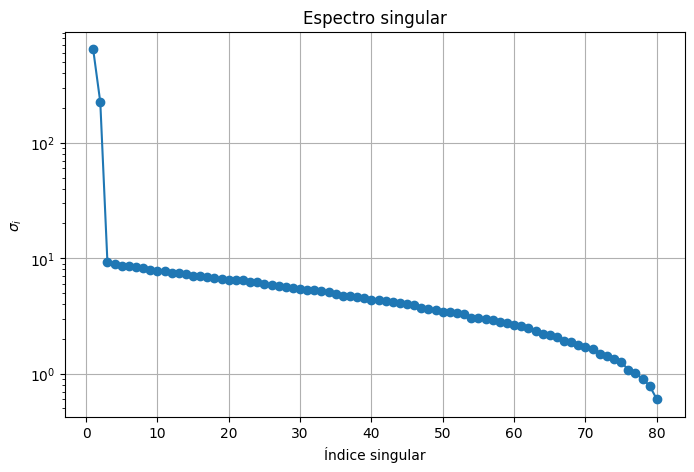

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

m = 100
n = 80

# Dos componentes dominantes
u1 = np.random.randn(m, 1)
v1 = np.random.randn(1, n)

u2 = np.random.randn(m, 1)
v2 = np.random.randn(1, n)

A = (
    8 * (u1 @ v1)
    + 3 * (u2 @ v2)
    + 0.5 * np.random.randn(m, n)
)

U, S, VT = np.linalg.svd(A, full_matrices=False)

plt.figure(figsize=(8, 5))

plt.semilogy(
    np.arange(1, len(S) + 1),
    S,
    "o-"
)

plt.xlabel("Índice singular")
plt.ylabel(r"$\sigma_i$")
plt.title("Espectro singular")
plt.grid(True)

plt.show()

Si existen solamente unos pocos valores singulares dominantes, tenemos una señal clara de estructura de bajo rango.

# 15. Aproximación de rango $(k)$ en Python

In [4]:
k = 2

A_k = (
    U[:, :k]
    @ np.diag(S[:k])
    @ VT[:k, :]
)

error = np.linalg.norm(A - A_k, "fro")

print("Error Frobenius:", error)

Error Frobenius: 44.42592014601955


Puedes comparar diferentes valores:

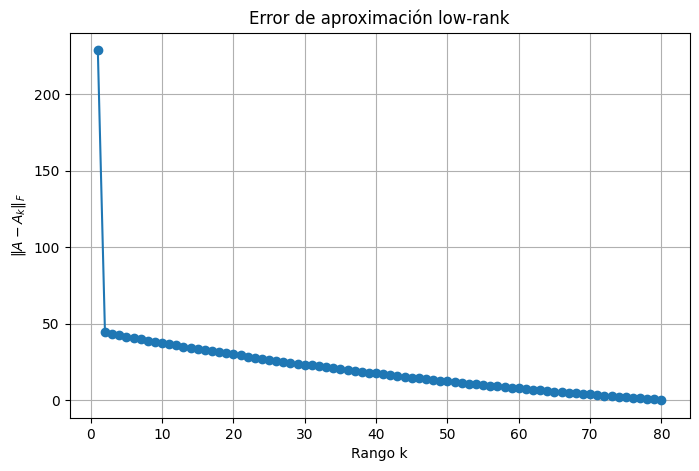

In [5]:
errors = []

for k in range(1, len(S) + 1):

    A_k = (
        U[:, :k]
        @ np.diag(S[:k])
        @ VT[:k, :]
    )

    error = np.linalg.norm(A - A_k, "fro")

    errors.append(error)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(S) + 1),
    errors,
    "o-"
)

plt.xlabel("Rango k")
plt.ylabel(r"$\|A-A_k\|_F$")
plt.title("Error de aproximación low-rank")
plt.grid(True)

plt.show()

# 16. Compresión de imágenes

Ahora una aplicación real muy conocida.

Una imagen puede representarse como una matriz:

$$
I\in\mathbb R^{m\times n}.
$$

Para una imagen en escala de grises:

$$
I_{ij}
$$

representa la intensidad del píxel.

Aplicamos:

$$
I=U\Sigma V^T.
$$

Podemos conservar solamente:

$$
k
$$

valores singulares:

$$
I_k=U_k\Sigma_kV_k^T.
$$

Entonces reducimos almacenamiento.

Originalmente:

$$
mn
$$

números.

Aproximación:

$$
mk+k+kn.
$$

Es decir:

$$
\boxed{
k(m+n+1)
}
$$

números.

Si:

$$
k\ll\min(m,n),
$$

podemos ahorrar muchísimo.

# 17. Código de compresión de imagen

Con una imagen disponible localmente:

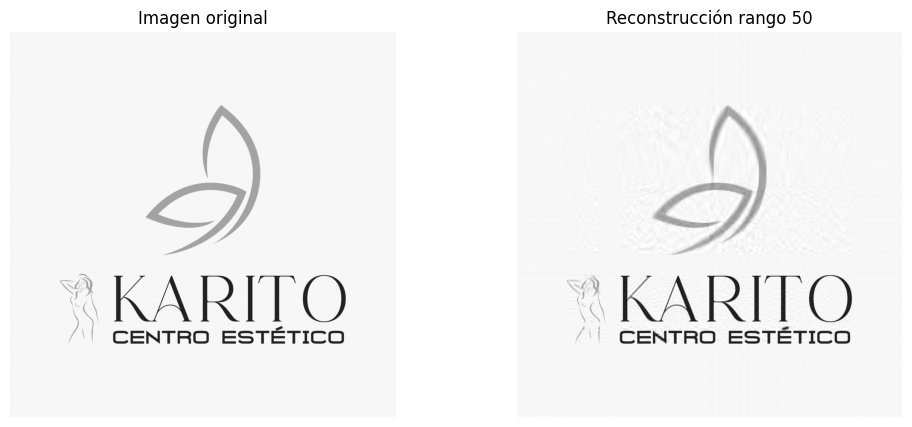

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image = Image.open("../img/Logo.jpg").convert("L")

A = np.array(image, dtype=float)

U, S, VT = np.linalg.svd(A, full_matrices=False)

k = 50

A_k = (
    U[:, :k]
    @ np.diag(S[:k])
    @ VT[:k, :]
)

A_k = np.clip(A_k, 0, 255)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(A, cmap="gray")
axes[0].set_title("Imagen original")
axes[0].axis("off")

axes[1].imshow(A_k, cmap="gray")
axes[1].set_title(f"Reconstrucción rango {k}")
axes[1].axis("off")

plt.show()

Prueba:

```python
k = 5
```

luego:

```python
k = 20
```

luego:

```python
k = 50
```

y:

```python
k = 100
```

Verás cómo la imagen recupera progresivamente los detalles.

# 18. ¿Qué está ocurriendo realmente?

Los valores singulares grandes representan estructuras importantes.

Los pequeños suelen representar:

* detalles finos;
* ruido;
* pequeñas variaciones.

Por eso conservar:

$$
\sigma_1,\ldots,\sigma_k
$$

permite conservar gran parte de la información.

Pero cuidado:

> **SVD no significa automáticamente que los valores singulares pequeños sean ruido.**

En datos científicos pueden contener información física importante.

# 19. Pseudoinversa

Ahora llegamos a algo fundamental para problemas inversos.

Supongamos:

$$
Ax=b.
$$

Si $(A)$ es cuadrada e invertible:

$$
x=A^{-1}b.
$$

Pero ¿qué pasa si $(A)$ no tiene inversa?

Por ejemplo:

$$
A=
\begin{bmatrix}
1&2\\
2&4
\end{bmatrix}.
$$

Esta matriz es singular.

Aquí utilizamos la **pseudoinversa de Moore–Penrose**:

$$
\boxed{A^+}
$$

y obtenemos:

$$
\boxed{
x=A^+b
}
$$

en el sentido apropiado.

# 20. Pseudoinversa mediante SVD

Si:

$$
A=U\Sigma V^T,
$$

entonces:

$$
\boxed{
A^+=V\Sigma^+U^T
}
$$

donde:

$$
\Sigma^+
$$

se obtiene tomando los recíprocos de los valores singulares no nulos.

Si:

$$
\Sigma=
\begin{bmatrix}
5&0\\
0&2
\end{bmatrix},
$$

entonces:

$$
\Sigma^+
=
\begin{bmatrix}
1/5&0\\
0&1/2
\end{bmatrix}.
$$

# 21. ¿Por qué es importante?

Porque nos permite resolver:

### Sistemas sobredeterminados

$$
m>n.
$$

Hay más ecuaciones que incógnitas.

### Sistemas subdeterminados

$$
m<n.
$$

Hay más incógnitas que ecuaciones.

### Sistemas singulares

No existe inversa ordinaria.

### Problemas mal condicionados

Pequeños errores en los datos pueden producir grandes errores en la solución.

# 22. Regresión lineal

Tenemos:

$$
X\beta\approx y.
$$

Queremos:

$$
\min_\beta
\|X\beta-y\|_2^2.
$$

Una solución de mínimos cuadrados puede expresarse como:

$$
\boxed{
\beta=X^+y
}
$$

La pseudoinversa aparece directamente.

Por eso SVD está relacionada con:

$$
\boxed{\text{Machine Learning}}
$$

desde el álgebra lineal.

# 23. Ejemplo difícil: regresión con características correlacionadas

Supongamos:

$$
X=
\begin{bmatrix}
1&1.001\\
2&2.001\\
3&3.001\\
4&4.001\\
5&5.001
\end{bmatrix}.
$$

Las columnas son casi iguales.

Entonces $(X)$ es casi de rango 1.

Los valores singulares serán aproximadamente:

$$
\sigma_1\gg\sigma_2.
$$

Esto indica que el problema está cerca de ser singular.

In [9]:
import numpy as np

X = np.array([
    [1, 1.001],
    [2, 2.001],
    [3, 3.001],
    [4, 4.001],
    [5, 5.001]
], dtype=float)

U, S, VT = np.linalg.svd(X)

print("Valores singulares:")
print(S)

print("Número de condición:")
print(S[0] / S[-1])

Valores singulares:
[1.04895188e+01 6.74107931e-04]
Número de condición:
15560.592469644154


La razón:

$$
\boxed{
\kappa(X)=\frac{\sigma_{\max}}{\sigma_{\min}}
}
$$

es el número de condición en norma 2 para una matriz de rango completo.

Si es enorme, el problema puede ser muy sensible.

# 24. Problemas inversos

Esta es una de las partes más importantes para SciML.

Un problema directo tiene la forma:

$$
\boxed{
x\rightarrow y
}
$$

mediante:

$$
y=Ax.
$$

Un problema inverso intenta hacer:

$$
\boxed{
y\rightarrow x
}
$$

es decir:

$$
Ax=y
$$

y queremos recuperar $(x)$.

# 25. Ejemplos reales de problemas inversos

### Tomografía

Tenemos:

$$
x=\text{estructura interna}
$$

y:

$$
y=\text{mediciones}.
$$

Queremos recuperar:

$$
x.
$$

### Geofísica

Tenemos mediciones sísmicas:

$$
y
$$

y queremos estimar:

$$
x=\text{estructura subterránea}.
$$

### Medicina

Tenemos señales medidas y queremos reconstruir:

* órganos;
* tejidos;
* parámetros fisiológicos.

### Astronomía

Observamos:

$$
y
$$

y queremos reconstruir propiedades del objeto físico:

$$
x.
$$

### SciML

Podemos tener:

$$
\boxed{
\text{PDE}
\rightarrow
\text{observaciones}
\rightarrow
\text{problema inverso}
\rightarrow
\text{parámetros físicos}
}
$$

Por ejemplo:

$$
u_t=\alpha u_{xx}
$$

y queremos encontrar:

$$
\alpha
$$

a partir de mediciones de $(u(x,t))$.

# 26. ¿Por qué los problemas inversos son difíciles?

Supongamos:

$$
y=Ax.
$$

Si:

$$
A
$$

tiene un valor singular muy pequeño:

$$
\sigma_{\min}\approx0,
$$

entonces:

$$
\frac1{\sigma_{\min}}
$$

es enorme.

Al utilizar la pseudoinversa:

$$
A^+
=
V\Sigma^+U^T,
$$

aparece:

$$
\frac1{\sigma_i}.
$$

Entonces cualquier ruido:

$$
\epsilon
$$

puede amplificarse muchísimo.

# 27. Ejemplo de amplificación del ruido

Supongamos:

$$
\sigma_1=10,
$$

$$
\sigma_2=10^{-6}.
$$

La pseudoinversa tiene:

$$
1/\sigma_1=0.1
$$

pero:

$$
1/\sigma_2=10^6.
$$

Un pequeño ruido de:

$$
10^{-5}
$$

en esa dirección puede transformarse en:

$$
10.
$$

¡Una enorme amplificación!

Esto es una de las razones por las cuales los problemas inversos pueden ser **ill-posed**.

# 28. Regularización

Para solucionar esto podemos no invertir directamente todos los valores singulares.

Una idea simple es **truncated SVD**:

$$
A_k^+
=
V_k\Sigma_k^{-1}U_k^T.
$$

Eliminamos los valores singulares demasiado pequeños.

En lugar de:

$$
\frac1{\sigma_i}
$$

para todos, solamente usamos los importantes.

# 29. Truncated SVD

Supongamos:

$$
\sigma_1=100,
\quad
\sigma_2=20,
\quad
\sigma_3=0.1,
\quad
\sigma_4=10^{-5}.
$$

Podemos decir:

$$
\sigma_4
$$

es demasiado pequeña para invertirla de forma confiable.

Entonces utilizamos:

$$
\boxed{
\sigma_4^{-1}\rightarrow0
}
$$

en la pseudoinversa regularizada.

Esto sacrifica cierta precisión pero puede mejorar muchísimo la estabilidad.

# 30. Código de pseudoinversa truncada

In [10]:
import numpy as np

def truncated_pseudoinverse(A, tolerance):

    U, S, VT = np.linalg.svd(
        A,
        full_matrices=False
    )

    S_inv = np.zeros_like(S)

    mask = S > tolerance

    S_inv[mask] = 1 / S[mask]

    A_pinv = (
        VT.T
        @ np.diag(S_inv)
        @ U.T
    )

    return A_pinv

Uso:

```python
A_pinv = truncated_pseudoinverse(
    A,
    tolerance=1e-4
)

x_est = A_pinv @ b
```

# 31. Reducción dimensional

Supongamos que tienes:

$$
X\in\mathbb R^{N\times d}.
$$

Quizás:

$$
d=1000.
$$

Pero la información real está concentrada en aproximadamente:

$$
k=20
$$

direcciones.

Entonces podemos utilizar SVD para representar:

$$
X\approx U_k\Sigma_kV_k^T.
$$

En lugar de trabajar con 1000 dimensiones podemos trabajar con:

$$
\boxed{k=20}.
$$

Esto puede acelerar:

* entrenamiento;
* visualización;
* almacenamiento;
* clustering;
* regresión;
* simulaciones.

# 32. PCA

Ahora llegamos a PCA.

Supongamos que tenemos datos centrados:

$$
X_c.
$$

La matriz de covarianza es:

$$
C=
\frac1{N-1}X_c^TX_c.
$$

PCA busca los autovectores de:

$$
C.
$$

Pero observa:

$$
X_c=U\Sigma V^T.
$$

Entonces:

$$
X_c^TX_c
=
V\Sigma^2V^T.
$$

Por tanto:

$$
\boxed{
\text{Los autovectores de la covarianza son los vectores singulares derechos de }X_c
}
$$

y:

$$
\boxed{
\lambda_i=\frac{\sigma_i^2}{N-1}
}
$$

¡Así que PCA y SVD están directamente conectados!

# 33. Interpretación de PCA

PCA busca nuevas direcciones:

$$
v_1,v_2,\ldots
$$

que maximicen la variabilidad de los datos.

La primera componente:

$$
v_1
$$

es la dirección de máxima varianza.

La segunda:

$$
v_2
$$

es la siguiente dirección ortogonal con máxima varianza.

Y así sucesivamente.

# 34. Ejemplo de PCA en Python

Vamos a generar datos correlacionados:

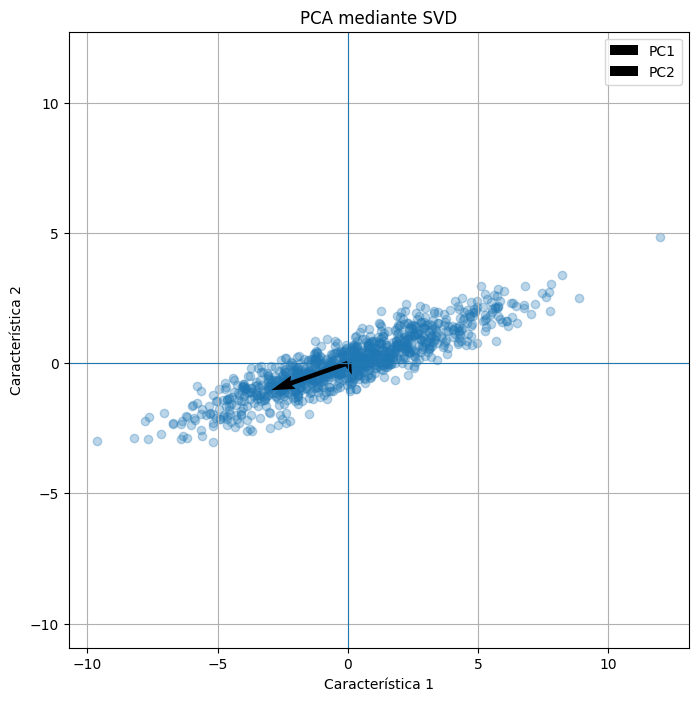

In [12]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

N = 1000

z1 = np.random.randn(N)
z2 = 0.3 * np.random.randn(N)

x = 3 * z1 + z2
y = z1 + 2 * z2

X = np.column_stack([x, y])

# Centrar
X_centered = X - X.mean(axis=0)

# SVD
U, S, VT = np.linalg.svd(
    X_centered,
    full_matrices=False
)

components = VT

plt.figure(figsize=(8, 8))

plt.scatter(
    X_centered[:, 0],
    X_centered[:, 1],
    alpha=0.3
)

origin = np.zeros(2)

for i in range(2):

    v = components[i]

    scale = S[i] / np.sqrt(N)

    plt.quiver(
        0,
        0,
        scale * v[0],
        scale * v[1],
        angles="xy",
        scale_units="xy",
        scale=1,
        linewidth=3,
        label=f"PC{i+1}"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Característica 1")
plt.ylabel("Característica 2")

plt.title("PCA mediante SVD")

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

La primera dirección debería atravesar la nube siguiendo su mayor elongación.

# 35. Explained variance

Los valores singulares permiten calcular la varianza explicada:

$$
\boxed{
r_k=
\frac{\sum_{i=1}^k\sigma_i^2}
{\sum_i\sigma_i^2}
}
$$

Por ejemplo:

$$
r_1=0.92.
$$

Significa que una sola dirección explica aproximadamente:

$$
92\%
$$

de la variabilidad.

Código:

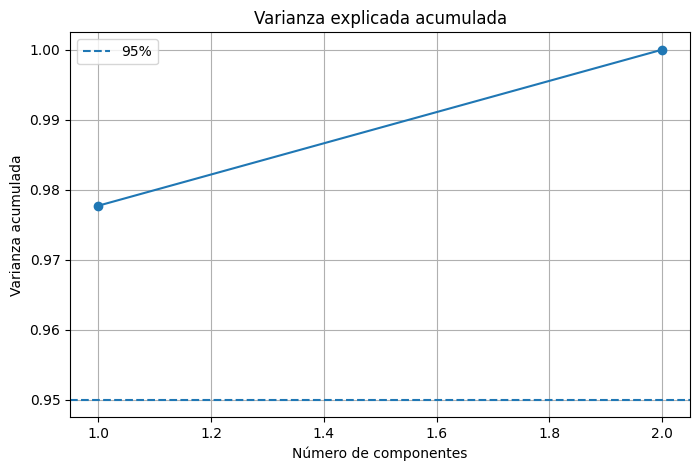

In [13]:
explained_variance_ratio = (
    S**2 / np.sum(S**2)
)

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(S) + 1),
    cumulative_variance,
    "o-"
)

plt.axhline(
    0.95,
    linestyle="--",
    label="95%"
)

plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.title("Varianza explicada acumulada")

plt.grid(True)
plt.legend()

plt.show()

# 36. Aplicación diaria: recomendaciones

Supongamos que tienes:

$$
X=
\begin{bmatrix}
\text{usuario 1}\\
\text{usuario 2}\\
\vdots
\end{bmatrix}
$$

y las columnas son:

* películas;
* canciones;
* productos;
* libros.

Tienes una matriz enorme:

$$
X\in\mathbb R^{N\times M}.
$$

SVD puede encontrar estructuras latentes:

$$
X\approx U_k\Sigma_kV_k^T.
$$

Los factores latentes pueden representar cosas como:

* acción;
* romance;
* ciencia ficción;
* deportes;
* etc.

No necesariamente tienen una interpretación semántica exacta, pero representan patrones ocultos de interacción.

Esta idea está relacionada con **recommender systems**.

# 37. Aplicación diaria: compresión

Una foto:

$$
2000\times3000
$$

tiene:

$$
6\,000\,000
$$

valores.

Si usamos:

$$
k=50,
$$

podemos almacenar aproximadamente:

$$
k(m+n+1)
$$

valores:

$$
50(2000+3000+1)
$$

$$
=250050.
$$

Comparado con:

$$
6\,000\,000.
$$

La representación es muchísimo menor.

La calidad dependerá de cuánto decaigan los valores singulares.

# 38. Aplicación científica: reducción de una simulación PDE

Este es uno de los ejemplos más importantes para **SciML**.

Supongamos que tienes una simulación:

$$
u(x,t).
$$

Guardas snapshots:

$$
u(x,t_1),
u(x,t_2),
\ldots,
u(x,t_N).
$$

Construyes:

$$
X=
\begin{bmatrix}
|&|&&|\\
u(t_1)&u(t_2)&\cdots&u(t_N)\\
|&|&&|
\end{bmatrix}.
$$

Entonces:

$$
X\in\mathbb R^{N_x\times N_t}.
$$

Haces:

$$
X=U\Sigma V^T.
$$

Si solamente necesitas:

$$
r=10
$$

modos:

$$
U_r=
[u_1,\ldots,u_r].
$$

Entonces:

$$
\boxed{
u(x,t)
\approx
\sum_{i=1}^{r}a_i(t)\phi_i(x)
}
$$

donde:

$$
\phi_i=u_i.
$$

Esto se llama **Proper Orthogonal Decomposition (POD)** y está estrechamente relacionado con PCA/SVD.

Esto es una conexión directa con:

$$
\boxed{
\text{SVD}\rightarrow\text{POD}\rightarrow\text{Reduced Order Models}\rightarrow\text{SciML}
}
$$

# 39. Ejemplo conceptual completo de SciML

Imagina una simulación CFD.

Tienes:

$$
N_x=100000
$$

grados de libertad.

Y:

$$
N_t=5000
$$

snapshots.

Entonces:

$$
X\in\mathbb R^{100000\times5000}.
$$

Eso es enorme.

Hacemos:

$$
X=U\Sigma V^T.
$$

Descubrimos:

$$
\sigma_1,\ldots,\sigma_{20}
$$

dominan.

Entonces:

$$
X\approx U_{20}\Sigma_{20}V_{20}^T.
$$

En lugar de describir el estado mediante:

$$
100000
$$

variables, podemos utilizar:

$$
20
$$

coeficientes.

Hemos pasado de:

$$
\boxed{
100000\rightarrow20
}
$$

grados de libertad efectivos.

Esto puede hacer posible ejecutar modelos reducidos muchísimo más rápido.

# 40. El gran problema: no confundas "dimensión" con "rango"

Supongamos:

$$
A\in\mathbb R^{1000\times100}.
$$

Su dimensión física como matriz es:

$$
1000\times100.
$$

Pero puede tener:

$$
\operatorname{rank}(A)=5.
$$

Entonces existen solamente cinco direcciones independientes efectivas.

Esto es precisamente lo que SVD puede revelar.

# 41. La imagen mental que debes conservar

Quiero que pienses en:

$$
\boxed{
A=U\Sigma V^T
}
$$

como:

```text
entrada
   │
   ▼
 Vᵀ
rotación/reflexión
   │
   ▼
 Σ
escalamiento de modos
   │
   ▼
 U
rotación/reflexión
   │
   ▼
salida
```

Y:

$$
\sigma_1\geq\sigma_2\geq\cdots
$$

te dice cuáles son los modos importantes.

# 42. El mapa completo

Ahora puedes conectar prácticamente todo lo que has estudiado:

$$
\boxed{
\text{Espacios vectoriales}
}
$$

↓

$$
\boxed{
\text{Subespacios}
}
$$

↓

$$
\boxed{
\text{Base + dimensión}
}
$$

↓

$$
\boxed{
\text{Transformaciones lineales}
}
$$

↓

$$
\boxed{
\text{Autovalores/autovectores}
}
$$

↓

$$
\boxed{
\text{SVD}
}
$$

↓

$$
\boxed{
\text{Rango}
}
$$

↓

$$
\boxed{
\text{Low-rank approximation}
}
$$

↓

$$
\boxed{
\text{PCA}
}
$$

↓

$$
\boxed{
\text{Reducción dimensional}
}
$$

↓

$$
\boxed{
\text{Problemas inversos}
}
$$

↓

$$
\boxed{
\text{Regularización}
}
$$

↓

$$
\boxed{
\text{Reduced-order modeling}
}
$$

↓

$$
\boxed{
\text{Scientific Machine Learning}
}
$$

| **Inicio**         | **atrás 4**                          | **Siguiente 6**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./2_4_Autovalores_y_autovectores.ipynb) | [⏩](./2_6_Algebra_lineal_numerica.ipynb) |